### helper function

In [1]:
import pandas as pd

# Hilfsfunktion für hübsche Addukt‑Namen
def pretty_adduct_name(name, latex=False):
    if name.endswith("+"):
        core = name[:-1]
        if latex:
            return fr"[{core}]$^{{+}}$"
        else:
            return f"[{core}]⁺"
    else:
        return f"[{name}]"

def load_hrms_excel(filename, max_mz_value, latex=False):
    sheets = pd.read_excel(filename, sheet_name=None)
    # erstes Blatt ("Elements") überspringen
    sheet_names = list(sheets.keys())[1:]
    
    all_data = []
    for name in sheet_names:
        df = sheets[name]
        df.columns = ["mz", "intensity", "struct ID", "Kendrick mass",
                      "KNM", "KMD", "Formula", "Adduct", "Ion", "Carbon number",
                      "DBE", "mz error ppm"]
        df["Adduct_from_sheet"] = pretty_adduct_name(name, latex=latex)
        all_data.append(df)
    df_all = pd.concat(all_data, ignore_index=True)
    return df_all[df_all["mz"] <= max_mz_value].copy()

### read xslx-files

In [3]:
excel_files = [
    ("Input/250828_Ar_pos_P_MS1_pos_ORBI_01_scan_34tol0-01_results_10ppm.xlsx", "Input/ORBI_0-01"),
    ("Input/250828_Ar_pos_P_MS1_pos_ORBI_01_scan_34tol0-001_results_10ppm.xlsx", "Input/ORBI_0-001"),
    ("Input/250828_Ar_pos_P_MS1_pos_ORBI_01_scan_34tol0-0001_results_10ppm.xlsx", "Input/ORBI_0-0001"),
    ("Input/250828_Ar_pos_P_MS1_pos_OSAF_03_cluster_scan_33tol0-001_results_10ppm.xlsx", "Input/OSAF_0-001")
]

max_mz = 750

if __name__ == "__main__":
    for file_path, output_name in excel_files:
        df = load_hrms_excel(file_path, max_mz, latex=False)  # oder latex=True für Plots
        out_filename = f"{output_name}.pkl"
        df.to_pickle(out_filename)
        print(f"[INFORMATION] saved: {out_filename} ({len(df)} Zeilen)")

[INFORMATION] saved: Input/ORBI_0-01.pkl (4506 Zeilen)
[INFORMATION] saved: Input/ORBI_0-001.pkl (7542 Zeilen)
[INFORMATION] saved: Input/ORBI_0-0001.pkl (8520 Zeilen)
[INFORMATION] saved: Input/OSAF_0-001.pkl (6783 Zeilen)


### Ion ratios

In [4]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os
import pandas as pd

def compare_isotope_ratios_df(
    df_all, 
    adduct_to_plot,              # must fit Adduct_from_sheet, i.e. "[M+O-3H]⁺"
    p_13C=0.0107,
    top_dbe_colors=5,
    sample="",
    ion_source="iLTP Ar(+) MS(+)",
    xlim_plot1=(3, 40), ylim_plot1=(0, 0.8), #modify for sample
    xlim_plot2=None, ylim_plot2=(20, 280),
    save_excel=True,
    output_prefix="plot"
):
    # --- Filter: only selected adduct ---
    df_adduct = df_all[df_all["Adduct_from_sheet"] == adduct_to_plot].copy()
    if df_adduct.empty:
        raise ValueError(
            f"[ERROR] Adduct '{adduct_to_plot}' not found!\n"
            f"Available Adducts: {list(df_all['Adduct_from_sheet'].unique())}"
        )

    # --- remove NaN / empty ---
    df_adduct["Formula"] = df_adduct["Formula"].astype(str).str.strip()
    df_adduct = df_adduct[
        (df_adduct["Formula"] != "") &
        (df_adduct["Formula"].str.lower() != "nan")
    ].copy()

    # --- differentiate in 13C1 and 12C ---
    df_13C1 = df_adduct[df_adduct["Formula"].str.endswith("13C1")].copy()
    df_12C  = df_adduct[~df_adduct["Formula"].str.endswith("13C1")].copy()

    # if empty → alert
    if df_13C1.empty or df_12C.empty:
        print(f"[WARN] No matching 13C1/12C-pairs found for {adduct_to_plot}.")
        return pd.DataFrame()

    # +1 C for 13C1 isotop
    df_13C1["Carbon number"] = df_13C1["Carbon number"].astype(float) + 1

    # --- merge ---
    cols = ["Carbon number", "DBE", "intensity", "Formula"]
    df_13C1 = df_13C1[cols].rename(columns={"intensity": "intensity_13C1", "Formula": "Formula_13C1"})
    df_12C  = df_12C[cols].rename(columns={"intensity": "intensity_12C",  "Formula": "Formula_12C"})
    df_pairs = pd.merge(df_12C, df_13C1, on=["Carbon number", "DBE"], how="inner")

    if df_pairs.empty:
        print(f"[WARN] No common carbon numbers/DBE found for {adduct_to_plot}.")
        return pd.DataFrame()

    # --- ratios ---
    df_pairs["ratio_13C1_to_12C"] = df_pairs["intensity_13C1"] / df_pairs["intensity_12C"]
    df_pairs["expected_ratio"] = df_pairs["Carbon number"] * p_13C / (1 - p_13C)
    df_pairs["percent_error"] = 100 * (df_pairs["ratio_13C1_to_12C"] - df_pairs["expected_ratio"]) / df_pairs["expected_ratio"]
    df_pairs["ratio_percent_theory"] = 100 * df_pairs["ratio_13C1_to_12C"] / df_pairs["expected_ratio"]

    df_pairs = df_pairs.sort_values(by=["Carbon number", "DBE"]).reset_index(drop=True)
    print(f"[INFO] Found isotope pairs for {adduct_to_plot}: {len(df_pairs)}")

    # --- colours ---
    palette = ["#004c93", "#ec7206", "#61a27c", "#b8103b", "#feca00"]
    default_color = "#dfe4f2"
    top_dbes = df_pairs["DBE"].value_counts().head(top_dbe_colors).index.tolist()
    color_map = {dbe: palette[i % len(palette)] for i, dbe in enumerate(top_dbes)}
    df_pairs["color"] = df_pairs["DBE"].apply(lambda d: color_map.get(d, default_color))
    mask_gray = df_pairs["color"] == default_color
    mask_color = ~mask_gray

    # --- plot parameters ---
    cm_to_inch = 0.393701
    fig_width = 16.5 * cm_to_inch
    fig_height = 5.0 * cm_to_inch
    label_fontsize = 7
    title_fontsize = 8
    tick_fontsize = 7
    legend_fontsize = 6

    # ---------- Plot 1 ----------
    plt.figure(figsize=(fig_width, fig_height), dpi=300)
    theory_line, = plt.plot(df_pairs["Carbon number"], df_pairs["expected_ratio"],
                            color="black", linestyle="-", linewidth=1.0, label="Theoretical")
    plt.scatter(df_pairs.loc[mask_gray, "Carbon number"],
                df_pairs.loc[mask_gray, "ratio_13C1_to_12C"],
                c=df_pairs.loc[mask_gray, "color"], edgecolors='black',
                linewidths=0.5, s=10)
    measured_scatter = plt.scatter(df_pairs.loc[mask_color, "Carbon number"],
                                   df_pairs.loc[mask_color, "ratio_13C1_to_12C"],
                                   c=df_pairs.loc[mask_color, "color"], edgecolors='black',
                                   linewidths=0.5, s=10, label="Measured data")
    plt.xlabel("Carbon number", fontsize=label_fontsize)
    plt.ylabel(f"Intensity ratio \n $^{1}$$^{3}$C$_1$ / $^{1}$$^{2}$C", fontsize=label_fontsize)
    plt.xticks(fontsize=tick_fontsize)
    plt.yticks(fontsize=tick_fontsize)
    if xlim_plot1: plt.xlim(*xlim_plot1)
    if ylim_plot1: plt.ylim(*ylim_plot1)
    plt.grid(True, linewidth=0.5)
    plt.suptitle("Measured and Theoretical Isotope Ratios", fontsize=title_fontsize,
                 fontweight='bold', x=0.36, y=0.94)
    plt.gcf().text(0.36, 0.84, f"{ion_source} – {sample}, Adduct: {adduct_to_plot}",
                   fontsize=label_fontsize, ha='center')
    legend_entries = [measured_scatter, theory_line] + \
                     [mpatches.Patch(color=col, label=f"DBE {dbe}") for dbe, col in color_map.items()]
    if mask_gray.any():
        legend_entries.append(mpatches.Patch(color=default_color, label="Other DBEs"))
    plt.legend(handles=legend_entries,
               loc='center left', bbox_to_anchor=(1.02, 0.5),
               fontsize=legend_fontsize)
    plt.tight_layout(rect=[0, 0, 0.8, 1])
    plt.savefig(f"Output/{output_prefix}_plot1.png", dpi=500, bbox_inches="tight")
    plt.show()

    # ---------- Plot 2 ----------
    plt.figure(figsize=(fig_width, fig_height), dpi=300)
    theory_line_hline, = plt.plot(df_pairs["Carbon number"],
                                  [100]*len(df_pairs),
                                  color="black", linestyle="--", linewidth=1.0,
                                  label="Theory = 100%")
    plt.scatter(df_pairs.loc[mask_gray, "Carbon number"],
                df_pairs.loc[mask_gray, "ratio_percent_theory"],
                c=df_pairs.loc[mask_gray, "color"], edgecolors='black',
                linewidths=0.3, s=20)
    percent_scatter = plt.scatter(df_pairs.loc[mask_color, "Carbon number"],
                                  df_pairs.loc[mask_color, "ratio_percent_theory"],
                                  c=df_pairs.loc[mask_color, "color"], edgecolors='black',
                                  linewidths=0.3, s=20, label="Measured data")
    plt.xlabel("Carbon number (total C atoms)", fontsize=label_fontsize)
    plt.ylabel(r"Measured ratio (% of theory)", fontsize=label_fontsize)
    plt.xticks(fontsize=tick_fontsize)
    plt.yticks(fontsize=tick_fontsize)
    if xlim_plot2: plt.xlim(*xlim_plot2)
    if ylim_plot2: plt.ylim(*ylim_plot2)
    plt.grid(True, linewidth=0.5)
    plt.suptitle("Measured Ratio as % of Theoretical Value",
                 fontsize=label_fontsize, fontweight='bold', y=1.02)
    plt.gcf().text(0.5, 0.94,
                   f"{ion_source} – {sample}, Adduct: {adduct_to_plot}",
                   fontsize=label_fontsize, ha='center')
    legend_entries2 = [percent_scatter, theory_line_hline] + \
                      [mpatches.Patch(color=col, label=f"DBE {dbe}") for dbe, col in color_map.items()]
    if mask_gray.any():
        legend_entries2.append(mpatches.Patch(color=default_color, label="Other DBEs"))
    plt.legend(handles=legend_entries2,
               loc='center left', bbox_to_anchor=(1.02, 0.5),
               fontsize=legend_fontsize)
    plt.tight_layout(rect=[0, 0, 0.8, 1])
    plt.savefig(f"Output/Ver2_{output_prefix}_plot2.png", dpi=300, bbox_inches="tight")
    plt.show()

    # --- Optional Excel speichern ---
    if save_excel:
        df_pairs.to_excel(f"Output/{output_prefix}_isotope_comparison.xlsx", index=True)
        print(f"[INFO] Saved results to: {output_prefix}_isotope_comparison.xlsx")

    return df_pairs

[INFO] Found isotope pairs for [M+O-3H]⁺: 147


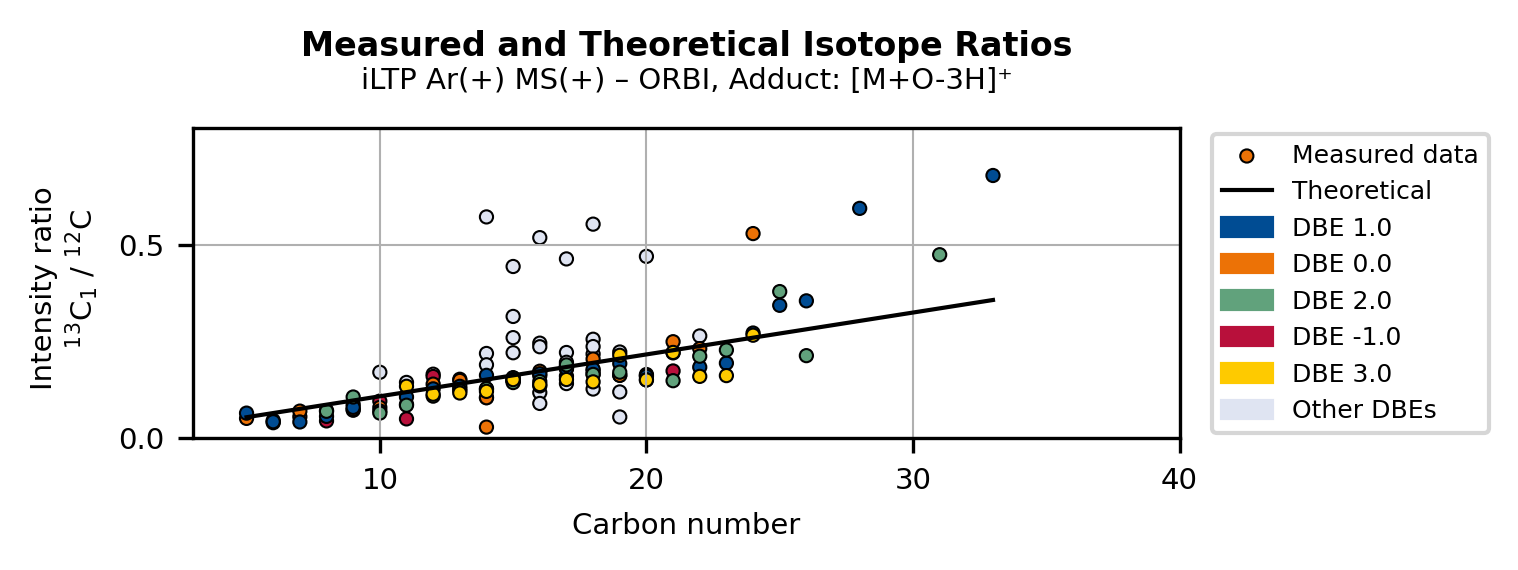

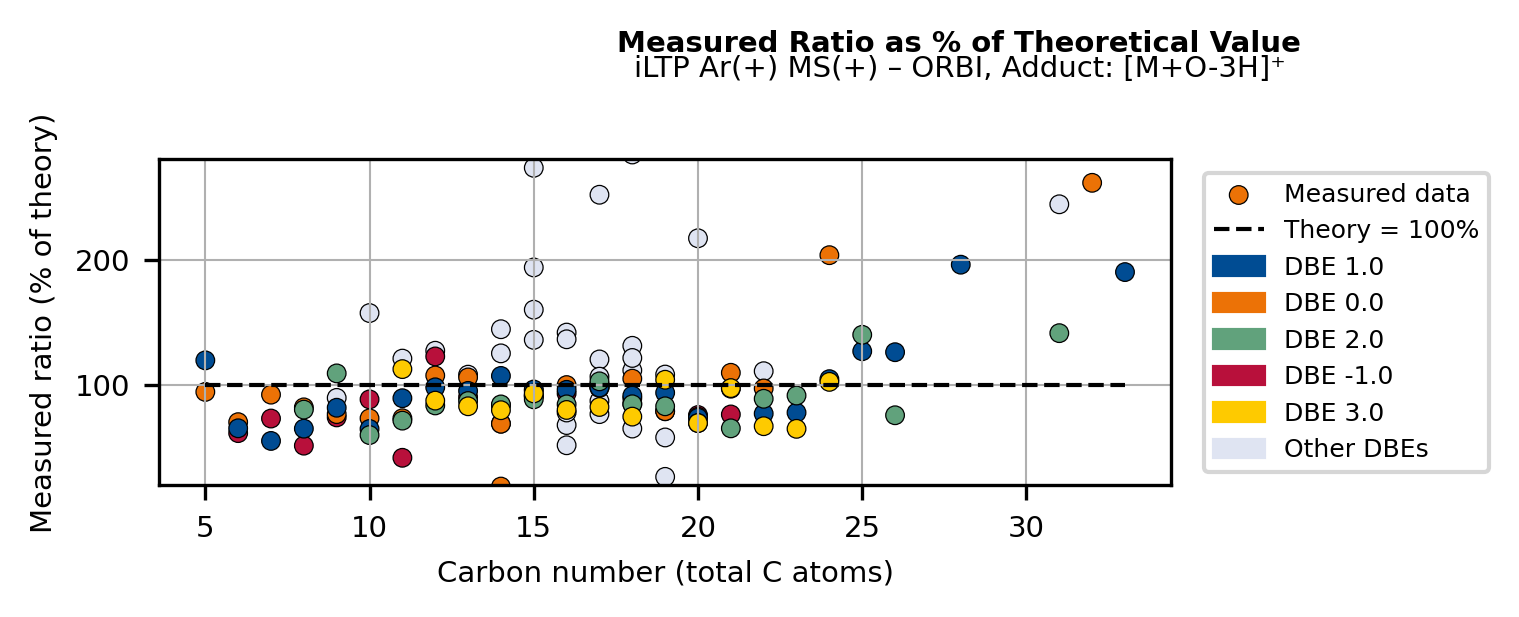

[INFO] Saved results to: ORBI_M+_13C_0-001_isotope_comparison.xlsx


,Carbon number,DBE,intensity_12C,Formula_12C,intensity_13C1,Formula_13C1,ratio_13C1_to_12C,expected_ratio,percent_error,ratio_percent_theory,color
0,5.0,0.0,37001775,C5H12,1889916,C4H1213C1,0.051076,0.054079,-5.551694,94.448306,#ec7206
1,5.0,1.0,6396857,C5H10,413838,C4H1013C1,0.064694,0.054079,19.629407,119.629407,#004c93
2,6.0,-1.0,8916984,C6H16,356144,C5H1613C1,0.039940,0.064894,-38.453888,61.546112,#b8103b
3,6.0,0.0,79613471,C6H14,3632179,C5H1413C1,0.045623,0.064894,-29.697031,70.302969,#ec7206
4,6.0,1.0,20580224,C6H12,873476,C5H1213C1,0.042442,0.064894,-34.597574,65.402426,#004c93
...,...,...,...,...,...,...,...,...,...,...,...
142,28.0,1.0,1076984,C28H56,639243,C27H5613C1,0.593549,0.302840,95.994069,195.994069,#004c93
143,31.0,2.0,772774,C31H60,366209,C30H6013C1,0.473889,0.335288,41.338035,141.338035,#61a27c
144,31.0,4.0,481932,C31H56,394616,C30H5613C1,0.818821,0.335288,144.214510,244.214510,#dfe4f2
145,32.0,0.0,413775,C32H66,374277,C31H6613C1,0.904542,0.346103,161.350386,261.350386,#ec7206


In [ ]:
import pandas as pd

# load pickle
df_loaded = pd.read_pickle("Input/ORBI_0-001.pkl") #select sample here

# call plot
compare_isotope_ratios_df(
    df_all=df_loaded,
    sample="ORBI",
    adduct_to_plot="[M+O-3H]⁺",
    output_prefix="ORBI_M+_13C_0-001"
)

### DBE vs C-number plots

version 1

In [23]:
cm = 1/2.54
plt.rcParams.update({
    "font.size": 8, #10 for report, 8 for publication
    "axes.labelsize": 8, #10 for report, 6 for publication
    "axes.titlesize": 8, #10 for report, 8 for publication
    "xtick.labelsize": 6, #10 for report, 8 for publication
    "ytick.labelsize": 6, #10 for report, 8 for publication
    "legend.fontsize": 8, #10 for report, 8 for publication
    "figure.titlesize": 8, #10 for report, 8 for publication
})

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# ==== colourscale ====
my_cmap = LinearSegmentedColormap.from_list(
    'my cmap',
    ['#ffffff', '#457B9D', '#355E80', '#2E5375',
     '#32664D', '#39AE29', '#40FF00',
     '#ffff00', '#ffc000', '#ff0000', '#C00000']
)

# ==== colourbar ====
def add_colorbar(fig, mappable, ax_for_height, label="Intensity", bar_width=0.02):
    """adds colourbar; height similar to 'ax_for_height'."""
    pos = ax_for_height.get_position()
    cax = fig.add_axes([0.92, pos.y0, bar_width, pos.height])
    cbar = plt.colorbar(mappable, cax=cax)
    cbar.ax.tick_params(labelsize=6)
    cbar.set_label(label, fontsize=6)

# ==== main ====
def plot_adduct_kendrick_df(
    df_all,
    adduct_to_plot="[M+O-3H]⁺",         # must fit "Adduct_from_sheet"
    ion_source="iLTP Ar(+) MS(+)",            
    sample="finished SAF",  
    bar_width=0.01
):
    """generates Kendrick-plots (12C vs 13C1) for defined adducts from loaded df."""

    # ---- Adduct filter ----
    df_adduct = df_all[df_all["Adduct_from_sheet"] == adduct_to_plot].copy()
    if df_adduct.empty:
        raise ValueError(f"[ERROR] Adduct '{adduct_to_plot}' nicht gefunden!\n"
                         f"Verfügbare: {df_all['Adduct_from_sheet'].unique()}")

    # ---- clean formula ----
    df_adduct["Formula"] = df_adduct["Formula"].astype(str).str.strip()
    df_adduct_with_formula = df_adduct[
        (df_adduct["Formula"] != "") &
        (df_adduct["Formula"].str.lower() != "nan")
    ].copy()

    print(f"[INFO] valid formulas found {adduct_to_plot}: {len(df_adduct_with_formula)}")

    # ---- differentiate 12C vs 13C1 ----
    df_13C1 = df_adduct_with_formula[df_adduct_with_formula["Formula"].str.endswith("13C1")].copy()
    df_12C  = df_adduct_with_formula[~df_adduct_with_formula["Formula"].str.endswith("13C1")].copy()

    # ---- sort ----
    df_13C1_sorted = df_13C1.sort_values(by="intensity", ascending=True)
    df_12C_sorted  = df_12C.sort_values(by="intensity", ascending=True)

    # ---- colourscale ----
    int_min = df_adduct_with_formula["intensity"].min()
    int_max = df_adduct_with_formula["intensity"].max()
    print(f"[INFO] colourscale for {adduct_to_plot}: Min={int_min}, Max={int_max} (valid formulas only)")

    # ---- similar y-scale ----
    ymin = min(df_12C["DBE"].min(), df_13C1["DBE"].min())
    ymax = max(df_12C["DBE"].max(), df_13C1["DBE"].max())

    # -------- Version 1: without lines --------
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16.5*cm, 5*cm), sharex=True, sharey=False)
    sc1 = ax1.scatter(df_12C_sorted["Carbon number"], df_12C_sorted["DBE"],
                      c=df_12C_sorted["intensity"], cmap=my_cmap,
                      edgecolors="gray", lw=0.5, s=40,
                      vmin=int_min, vmax=int_max)
    ax1.set_xlabel("Carbon Number")
    ax1.set_ylabel("DBE")
    ax1.set_title(f"{ion_source} - {sample}\nAdduct: {adduct_to_plot} (only $^{{12}}$C)")
    ax1.tick_params(axis='both')
    ax1.set_ylim(ymin, ymax)

    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)

    sc2 = ax2.scatter(df_13C1_sorted["Carbon number"], df_13C1_sorted["DBE"],
                      c=df_13C1_sorted["intensity"], cmap=my_cmap,
                      edgecolors="gray", lw=0.5, s=40,
                      vmin=int_min, vmax=int_max)
    ax2.set_xlabel("Carbon Number")
    ax2.set_ylabel("DBE")
    ax2.set_title(f"{ion_source} - {sample}\nAdduct: {adduct_to_plot} (1×$^{{13}}$C)")
    ax2.tick_params(axis='both')
    ax2.set_ylim(ymin, ymax)

    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)

    plt.subplots_adjust(right=0.9)
    add_colorbar(fig, sc1, ax2, label="Intensity", bar_width=bar_width)
    plt.show()

    # -------- Version 2: with lines --------
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16.5*cm, 5*cm), sharex=True, sharey=False)
    fig.subplots_adjust(
        left=0.08,
        right=0.98,
        top=0.8,
        bottom=0.2
    )
    sc1 = ax1.scatter(df_12C_sorted["Carbon number"], df_12C_sorted["DBE"],
                      c=df_12C_sorted["intensity"], cmap=my_cmap,
                      edgecolors="gray", lw=0.5, s=40,
                      vmin=int_min, vmax=int_max)
    ax1.set_xlabel("Carbon Number")
    ax1.set_ylabel("DBE",)
    ax1.set_title(f"{ion_source} - {sample}\nAdduct: {adduct_to_plot} (only $^{{12}}$C)")
    ax1.set_ylim(-1, 6)
    ax1.set_xlim(0, 38)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    for y in range(0, 7):
        ax1.axhline(y, color="black", ls="--", lw=1)
    ax1.tick_params(axis='both')

    sc2 = ax2.scatter(df_13C1_sorted["Carbon number"], df_13C1_sorted["DBE"],
                      c=df_13C1_sorted["intensity"], cmap=my_cmap,
                      edgecolors="gray", lw=0.5, s=40,
                      vmin=int_min, vmax=int_max)
    ax2.set_xlabel("Carbon Number")
    ax2.set_ylabel("DBE")
    ax2.set_title(f"{ion_source} - {sample}\nAdduct: {adduct_to_plot} (1×$^{{13}}$C)")
    ax2.set_ylim(-1, 6)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    for y in range(0, 7):
        ax2.axhline(y, color="black", ls="--", lw=1)
    ax2.tick_params(axis='both')

    plt.subplots_adjust(right=0.9)
    add_colorbar(fig, sc1, ax2, label="Intensity", bar_width=bar_width)

    plt.savefig("Ver2_OSAF_13C_0.0001.png", dpi=1200)
    plt.show()

[INFO] Gefundene gültige Formeln für [M+O-3H]⁺: 2840
[INFO] Farbskala für [M+O-3H]⁺: Min=241775, Max=400940305 (nur gültige Formeln)


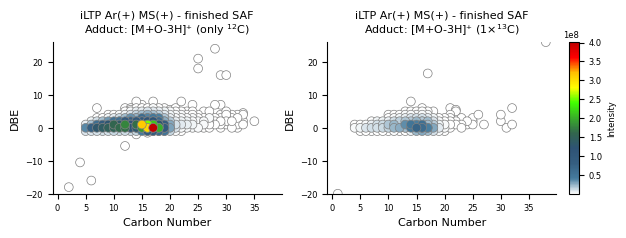

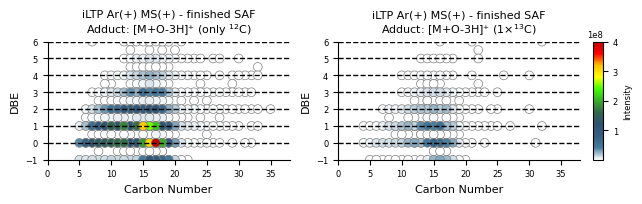

In [ ]:
import pandas as pd

# load pickle
df_loaded = pd.read_pickle("Input/ORBI_0-0001.pkl")

# call funcition
plot_adduct_kendrick_df(
    df_all=df_loaded,
    adduct_to_plot="[M+O-3H]⁺", 
    ion_source="iLTP Ar(+) MS(+)",
    sample="finished SAF",
    bar_width=0.015
)